# Forecasting US Electricity Prices

**How accurately can the average US price of electricity be forecast 1–12 months ahead, using price history alone?**

*An AI-assisted revision of my M.S. Data Analytics capstone (WGU, 2026), produced with Claude (Anthropic). The original, as submitted, is in [`D214-capstone-electricity-price-forecast/`](../../D214-capstone-electricity-price-forecast/). The section [Revisiting the original capstone](#Revisiting-the-original-capstone) lists what changed and why.*

## Summary

- **Data:** the monthly average US retail price of electricity (BLS, via [FRED series APU000072610](https://fred.stlouisfed.org/series/APU000072610)), March 2016 to March 2026.
- **Method:** I compared two SARIMA specifications, exponential smoothing (ETS) and three simple baselines in a **rolling-origin backtest**. From each of 25 starting points (quarterly, March 2019 to March 2025), every model forecasts the next 12 months, and its errors are averaged.
- **Result:** every method lands within a few percent. **A fixed, standard SARIMA was the most accurate overall (2.5% average error over 1–12 months) and the most consistent, ahead of a straight-line trend (drift, 2.7%) and exponential smoothing (2.8%).** The automatically selected SARIMA, set up as in my original capstone, did less well (3.3%). How the model was specified mattered more than which family it came from. Seasonality is weak, so most of the error comes from shifts in the price level, above all the 2021–22 surge.
- **What revisiting the original showed.** My capstone scored SARIMA on a single 30-month test window and reported 0.77% MAPE. Testing that setup further showed the figure is sensitive to small details: it ranges from 0.8% to 2.4% depending on the units and on how the one missing month is handled. That finding is what led to the broader backtest and the baseline comparison here.
- **How it held up.** Seven months of new prices (April to October 2026) were published after the analysis was finished. The fixed SARIMA was the most accurate on them (1.4%). The averaged forecast committed beforehand was off by 1.5%, in line with the backtest, and its 80% interval contained four of the seven prices.
- **Forecast:** an average of the drift, ETS and SARIMA forecasts puts prices at **about 19.6¢/kWh by March 2027**, up about 3% from 19.0¢ in March 2026 (80% interval: 19.1–21.8¢). The fixed SARIMA alone gives 19.9¢.

## 1. Why this matters

Electricity is an input to nearly everything. An OECD panel study estimates that a 10% rise in energy prices reduces GDP growth by about 0.15 percentage points, and by more in energy-intensive economies (Huntington & Liddle, 2022). Demand from data centers has put US retail prices back in the news (Bensaidani & Deveaux, 2026). Budgeting, procurement and household planning all depend on knowing how far ahead price history can usefully forecast prices, and how much error to expect.

**The original hypothesis.** The capstone rubric required a null and an alternative hypothesis, so the original asked whether a forecast with a MAPE under 10% could be built from price history (the null being that it couldn't). That test is kept here, and section 6 reports it. Its limitation is that a fixed threshold can't distinguish a strong model from a trivial one, so the main question in this revision is how each model compares with simple baselines.

In [1]:
import warnings
warnings.filterwarnings("ignore")  # statsmodels convergence chatter; fits are checked via the backtest

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pmdarima import auto_arima
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.precision", 2)

# Chart styling: neutral ink for history, a fixed categorical order for models
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
COLORS = {
    "Naive": "#2a78d6",
    "Seasonal naive": "#eb6834",
    "Drift": "#1baf7a",
    "ETS": "#eda100",
    "SARIMA (auto-selected)": "#e87ba4",
    "SARIMA (fixed)": "#6250d6",
    "Average (drift, ETS, SARIMA)": "#008300",
}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})

## 2. Data

The series is the Bureau of Labor Statistics' *average price of electricity per kilowatt-hour, U.S. city average*, collected for the CPI and republished on FRED. I downloaded it as a CSV covering March 2016 to March 2026. (A second file with later months is used only in section 9.) Two caveats: it's a national average of utility bills, so it isn't suitable for comparing places (BLS, 2026), and FRED's terms allow non-commercial use with attribution.

I work in **cents per kWh** for readability.

In [2]:
raw = pd.read_csv("data/APU000072610.csv", parse_dates=["observation_date"], index_col="observation_date")
price = (raw["APU000072610"] * 100).rename("cents_per_kwh").asfreq("MS")

print(f"{price.index.min():%b %Y} to {price.index.max():%b %Y}: {len(price)} months")
print("Missing months:", [f"{d:%b %Y}" for d in price[price.isna()].index])
print(price.loc["2025-08":"2025-12"])

Mar 2016 to Mar 2026: 121 months
Missing months: ['Oct 2025']
observation_date
2025-08-01    19.0
2025-09-01    18.8
2025-10-01     NaN
2025-11-01    18.9
2025-12-01    18.9
Freq: MS, Name: cents_per_kwh, dtype: float64


October 2025 is missing because of the federal government shutdown that month: BLS didn't collect the prices, so the value doesn't exist. The original capstone dropped the row. Revisiting it, I found that dropping leaves a gap in a series the models treat as evenly spaced, so every later month sits one position early. Here the gap is filled by **linear interpolation** between September (18.8¢) and November (18.9¢), which gives the models an evenly spaced series. A filled value isn't a real observation, so **it is never used to score a forecast**.

In [3]:
FILLED = price[price.isna()].index  # months with no real observation; excluded from all scoring
price = price.interpolate()
assert price.isna().sum() == 0 and pd.infer_freq(price.index) == "MS"
price.describe()

count    121.00
mean      15.22
std        1.95
min       13.10
25%       13.60
50%       14.20
75%       16.90
max       19.20
Name: cents_per_kwh, dtype: float64

## 3. What the series looks like

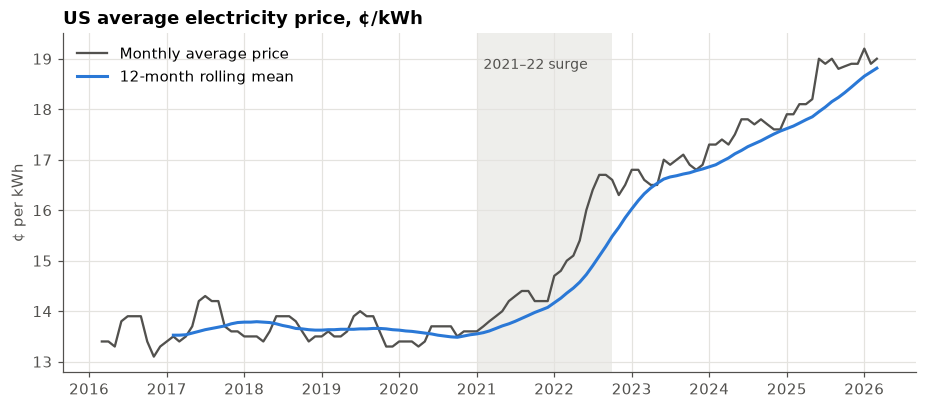

Year-over-year change in annual average price (%):
observation_date
2017-01-01     1.7
2018-01-01    -1.1
2019-01-01     0.1
2020-01-01    -0.7
2021-01-01     4.0
2022-01-01    12.6
2023-01-01     6.1
2024-01-01     4.5
2025-01-01     5.6
2026-01-01     2.6
Freq: YS-JAN


In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(pd.Timestamp("2021-01-01"), pd.Timestamp("2022-10-01"), color=GRID, alpha=0.6, lw=0)
ax.plot(price, color=INK_2, lw=1.5, label="Monthly average price")
ax.plot(price.rolling(12).mean(), color=COLORS["Naive"], label="12-month rolling mean")
ax.text(pd.Timestamp("2021-02-01"), 18.8, "2021–22 surge", color=INK_2, fontsize=9)
ax.set(title="US average electricity price, ¢/kWh", ylabel="¢ per kWh")
ax.legend(loc="upper left")
plt.show()

growth = price.resample("YS").mean().pct_change().mul(100).dropna()
print("Year-over-year change in annual average price (%):")
print(growth.round(1).to_string())

Prices were nearly flat from 2016 to 2020, at about 13–14¢, rose about 23% between early 2021 and late 2022 (13.6¢ to 16.7¢), and have kept climbing more slowly since. That shift in level is the hardest part to forecast: nothing in the series before 2021 predicts it.

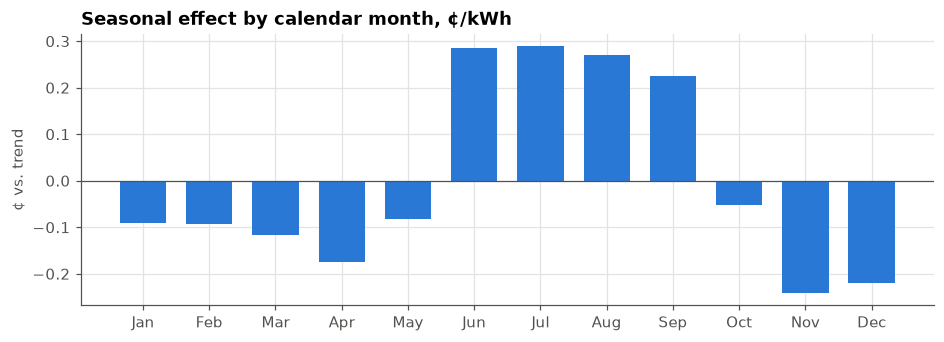

Peak-to-trough seasonal swing: 0.53¢, about 3.5% of the average price


In [5]:
decomp = seasonal_decompose(price, model="additive", period=12)
season = decomp.seasonal.groupby(decomp.seasonal.index.month).mean()
season.index = pd.to_datetime(season.index, format="%m").strftime("%b")

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(season.index, season.values, color=COLORS["Naive"], width=0.7)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set(title="Seasonal effect by calendar month, ¢/kWh", ylabel="¢ vs. trend")
plt.show()

amp = season.max() - season.min()
print(f"Peak-to-trough seasonal swing: {amp:.2f}¢, about {amp / price.mean():.1%} of the average price")

There is a summer peak, but it's small: about 0.5¢, or roughly 3.5% of the average price from trough to peak. Changes in level matter far more than the seasonal pattern, which suggests a seasonal-naive forecast (repeat last year) will do badly and trend-following methods will do well.

## 4. How stable is a single test window?

The original capstone fitted SARIMA(0,1,1)(0,1,2)₁₂ to all but the last 30 months, then scored a single 30-month forecast. To see how stable that result is, the table repeats the setup three ways. The first row is the original exactly, in $/kWh with the missing month dropped. The second row is the same data in ¢/kWh. The third row is in ¢/kWh with the gap interpolated (and not scored), which moves the split by one month. A drift forecast is included for comparison, and every SARIMA fit converged.

In [6]:
def mape(actual, forecast):
    actual, forecast = np.asarray(actual), np.asarray(forecast)
    return 100 * np.mean(np.abs(actual - forecast) / np.abs(actual))


def capstone_sarima(series, horizon):
    train, test = series.iloc[:-horizon], series.iloc[-horizon:]
    fit = SARIMAX(train, order=(0, 1, 1), seasonal_order=(0, 1, 2, 12), trend="c", freq="MS").fit(disp=False)
    return train, test, fit.forecast(horizon).values, fit.mle_retvals["converged"]


dollars_dropped = raw["APU000072610"].dropna()
setups = [("Original: $/kWh, missing month dropped", dollars_dropped),
          ("Same data in ¢/kWh", dollars_dropped * 100),
          ("¢/kWh, missing month interpolated", price)]
rows = []
for label, series in setups:
    train, test, fc, converged = capstone_sarima(series, 30)
    drift = train.iloc[-1] + (train.iloc[-1] - train.iloc[0]) / (len(train) - 1) * np.arange(1, 31)
    real = ~test.index.isin(FILLED)  # score only months with a real observation
    rows.append({"setup": label, "train ends": f"{train.index[-1]:%b %Y}",
                 "SARIMA MAPE %": mape(test[real], fc[real]), "Drift MAPE %": mape(test[real], drift[real]),
                 "SARIMA converged": converged})
pd.DataFrame(rows).set_index("setup")

,train ends,SARIMA MAPE %,Drift MAPE %,SARIMA converged
setup,,,,
"Original: $/kWh, missing month dropped",Aug 2023,0.77,2.19,True
Same data in ¢/kWh,Aug 2023,1.78,2.19,True
"¢/kWh, missing month interpolated",Sep 2023,2.36,1.99,True


The same model on the same data scores 0.8% or 1.8% depending only on whether prices are recorded in dollars or cents. The likelihood is flat enough that the optimizer settles on different parameters, and a 30-month forecast amplifies the difference. With the gap filled, SARIMA scores 2.4%, a little behind a straight-line drift. None of this means the original fit was wrong. It means a single test window measures one fit on one stretch of history, and can't show how reliable the method is in general.

Two smaller details are also corrected from here on. MAPE's arguments were in the order `(forecast, actual)`, which changed the result only in the third decimal place. And with the October row dropped, the last five forecasts were each compared with the following month's price.

So the rest of this analysis uses a **rolling-origin backtest**: forecast from many starting points and average the errors.

## 5. Models and evaluation design

| Model | What it does |
|---|---|
| **Naive** | Repeats the last observed price. |
| **Seasonal naive** | Repeats the last 12 months. |
| **Drift** | Extends the average monthly change across the training history in a straight line. |
| **ETS** | Holt–Winters exponential smoothing with a damped additive trend and additive seasonality. |
| **SARIMA (auto-selected)** | Seasonal ARIMA with D = 1, m = 12 and an intercept, as in the original capstone. `auto_arima` picks the order by AIC, re-selected at every forecast origin, so no future data leaks into model choice. |
| **SARIMA (fixed)** | SARIMA(0,1,1)(0,1,1)₁₂ with no constant. This is the standard "airline" model, a common default for monthly seasonal data, with the same structure at every origin. |
| **Average** | The mean of the Drift, ETS and auto-selected SARIMA forecasts. Averaging different methods is a robust default (Hyndman & Athanasopoulos, 2021). |

**Backtest:** 25 forecast origins, one per quarter from March 2019 to March 2025. At each origin, every model is refitted on all data up to that month and forecasts the next 12 months. The earliest origin has 37 months of training data, and the latest forecast ends in March 2026. Error is measured with **MAPE**, which is easy to read for a price series with no zeros, and with **MAE in cents**. The interpolated October 2025 value is left out of the scoring.

**A note on the fixed SARIMA.** It was added after the rest of this analysis. I first used it in the [natural gas extension](natural_gas_extension.ipynb) as a neutral reference model, saw that it outperformed the auto-selected SARIMA, and brought it into this backtest. Because it was added after seeing that result, its lead here should be read with some caution. The average is left as originally defined, since its forecast was committed before the new data in section 9 arrived.

**Why 1–12 months, when the original tested 30?** Error grows with the horizon, so it's reported month by month instead of as one blended figure. Twelve months matches annual budgeting and contract cycles. And ten years of data doesn't contain enough separate 30-month periods to test a horizon that long with any confidence.

In [7]:
HORIZON = 12
ORIGINS = pd.date_range("2019-03-01", "2025-03-01", freq="3MS")


def drift_forecast(train, h):
    slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
    return train.iloc[-1] + slope * np.arange(1, h + 1)


def ets_forecast(train, h):
    model = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12)
    return model.fit().forecast(h).values


def sarima_auto_forecast(train, h):
    model = auto_arima(train, m=12, D=1, with_intercept=True, suppress_warnings=True, error_action="ignore")
    return model.predict(h).values


def sarima_fixed_forecast(train, h):
    fit = SARIMAX(train, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    return fit.forecast(h).values


MODELS = {
    "Naive": lambda tr, h: np.repeat(tr.iloc[-1], h),
    "Seasonal naive": lambda tr, h: np.resize(tr.iloc[-12:].values, h),
    "Drift": drift_forecast,
    "ETS": ets_forecast,
    "SARIMA (auto-selected)": sarima_auto_forecast,
    "SARIMA (fixed)": sarima_fixed_forecast,
}


def forecast_all(train, h):
    fc = {name: f(train, h) for name, f in MODELS.items()}
    fc["Average (drift, ETS, SARIMA)"] = np.mean([fc["Drift"], fc["ETS"], fc["SARIMA (auto-selected)"]], axis=0)
    return fc


records = []
for origin in ORIGINS:
    train = price[:origin]
    actual = price[origin + pd.DateOffset(months=1):].iloc[:HORIZON]
    for name, fc in forecast_all(train, HORIZON).items():
        for h, (date, y, f) in enumerate(zip(actual.index, actual.values, fc), start=1):
            if date in FILLED:
                continue  # interpolated month: not a real observation, so not scored
            records.append({"origin": origin, "model": name, "h": h, "actual": y, "forecast": f})

bt = pd.DataFrame(records)
bt["abs_err"] = (bt["actual"] - bt["forecast"]).abs()
bt["ape"] = 100 * bt["abs_err"] / bt["actual"]
print(f"{bt['origin'].nunique()} origins × {bt['model'].nunique()} models × up to {HORIZON} horizons = {len(bt):,} scored forecasts")

25 origins × 7 models × up to 12 horizons = 2,086 scored forecasts


## 6. Results

In [8]:
order = ["SARIMA (fixed)", "Average (drift, ETS, SARIMA)", "Drift", "ETS", "SARIMA (auto-selected)", "Naive", "Seasonal naive"]
summary = pd.DataFrame({
    "MAPE %, 1–12 mo": bt.groupby("model")["ape"].mean(),
    "MAE ¢, 1–12 mo": bt.groupby("model")["abs_err"].mean(),
    **{f"MAPE % at {h} mo": bt[bt["h"] == h].groupby("model")["ape"].mean() for h in (1, 3, 6, 12)},
}).loc[order]

worst = bt.groupby(["model", "h"])["ape"].mean().max()
print(f"Original hypothesis (MAPE < 10%): the highest average MAPE for any model at any horizon is {worst:.1f}%")
summary

Original hypothesis (MAPE < 10%): the highest average MAPE for any model at any horizon is 5.5%


,"MAPE %, 1–12 mo","MAE ¢, 1–12 mo",MAPE % at 1 mo,MAPE % at 3 mo,MAPE % at 6 mo,MAPE % at 12 mo
model,,,,,,
SARIMA (fixed),2.48,0.39,0.73,1.40,2.46,3.68
"Average (drift, ETS, SARIMA)",2.58,0.41,0.73,1.41,2.48,4.12
Drift,2.69,0.43,1.04,2.06,3.05,3.94
ETS,2.77,0.45,0.78,1.41,2.52,4.62
SARIMA (auto-selected),3.34,0.53,0.82,1.74,3.17,5.52
Naive,3.20,0.52,1.01,2.14,3.38,5.31
Seasonal naive,4.96,0.81,4.59,4.72,4.93,5.31


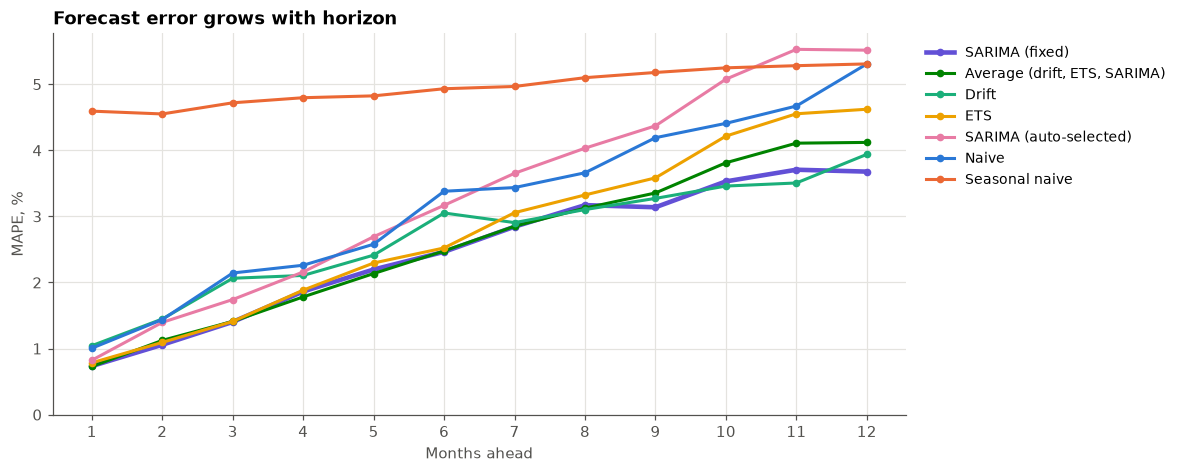

In [9]:
by_h = bt.groupby(["model", "h"])["ape"].mean().unstack("model")

fig, ax = plt.subplots(figsize=(10, 4.5))
for name in order:
    lw = 3 if name == "SARIMA (fixed)" else 2
    ax.plot(by_h.index, by_h[name], color=COLORS[name], lw=lw, marker="o", ms=4, label=name)
ax.set(title="Forecast error grows with horizon", xlabel="Months ahead", ylabel="MAPE, %",
       xticks=range(1, 13), ylim=(0, None))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.show()

- **The fixed SARIMA is the most accurate model overall** (2.5% over 1–12 months). It matches the best methods at short horizons (0.7% one month out, 1.4% at three) and stays level with drift at twelve (3.7% against 3.9%).
- **The auto-selected SARIMA does less well** (3.3% overall, 5.5% at twelve months), about level with the naive forecast. The two SARIMA models differ only in specification: the auto-selected one includes an intercept and changes structure from origin to origin.
- **ETS and the average are strong for the first few months** (0.7–0.8% one month out) and fall behind drift by twelve months (4.6% and 4.1% against 3.9%).
- **Seasonal naive is the least accurate at almost every horizon,** as the weak seasonality in section 3 suggested.
- **The original hypothesis holds, for every model.** The highest average MAPE for any model at any horizon is 5.5%, well under the 10% threshold, so the null hypothesis is rejected, as it was in the original. Because even the simplest baseline passes, the comparison between models is the more informative result.

The averages above come from only 25 forecast origins, so it's worth checking how consistent the pattern is. This table counts the origins where each statistical model was more accurate than drift:

In [10]:
def wins(model, baseline, horizons):
    err = bt[bt["h"].isin(horizons)].groupby(["origin", "model"])["abs_err"].mean().unstack()
    return f"{(err[model] < err[baseline]).sum()} of {len(err)}"


CHECK = ("SARIMA (fixed)", "SARIMA (auto-selected)", "ETS")
pd.DataFrame(
    {"Months 1–3": [wins(m, "Drift", [1, 2, 3]) for m in CHECK],
     "Months 10–12": [wins(m, "Drift", [10, 11, 12]) for m in CHECK]},
    index=[f"{m} more accurate than drift" for m in CHECK],
)

,Months 1–3,Months 10–12
SARIMA (fixed) more accurate than drift,19 of 25,17 of 25
SARIMA (auto-selected) more accurate than drift,12 of 25,9 of 25
ETS more accurate than drift,18 of 25,9 of 25


The fixed SARIMA is the only model that beats drift consistently at both ends: from 19 of the 25 origins at one to three months, and from 17 at ten to twelve. ETS is consistent at short horizons (18 of 25) but not at long ones (9 of 25). The auto-selected SARIMA beats drift from about half the origins at short horizons (12 of 25) and fewer at long ones (9 of 25). With 25 origins these counts are suggestive, not conclusive.

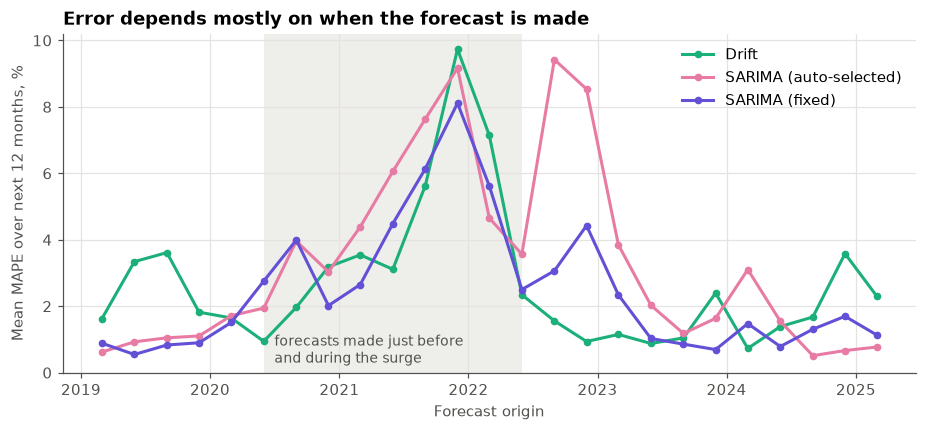

era,2019 – early 2020,mid-2020 – mid-2022,mid-2022 – 2025
model,,,
SARIMA (fixed),0.94,4.47,1.78
"Average (drift, ETS, SARIMA)",1.17,4.55,1.85
Drift,2.41,4.41,1.65
ETS,0.95,4.46,2.41
SARIMA (auto-selected),1.08,5.10,3.10
Naive,2.14,4.76,2.60
Seasonal naive,1.21,6.62,5.42


In [11]:
per_origin = bt.groupby(["origin", "model"])["ape"].mean().unstack("model")
show = ["Drift", "SARIMA (auto-selected)", "SARIMA (fixed)"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(pd.Timestamp("2020-06-01"), pd.Timestamp("2022-06-01"), color=GRID, alpha=0.6, lw=0)
for name in show:
    ax.plot(per_origin.index, per_origin[name], color=COLORS[name], marker="o", ms=4, label=name)
ax.text(pd.Timestamp("2020-07-01"), 0.3, "forecasts made just before\nand during the surge", color=INK_2, fontsize=9)
ax.set(title="Error depends mostly on when the forecast is made", xlabel="Forecast origin",
       ylabel="Mean MAPE over next 12 months, %", ylim=(0, None))
ax.legend(loc="upper right")
plt.show()

era = np.where(bt["origin"] < "2020-06-01", "2019 – early 2020",
               np.where(bt["origin"] < "2022-06-01", "mid-2020 – mid-2022", "mid-2022 – 2025"))
bt.assign(era=era).pivot_table(index="model", columns="era", values="ape", aggfunc="mean").loc[order]

Most of the error comes from forecasts made just before or during the 2021–22 surge. No model using only price history could see it coming, so they all miss it by a similar amount. The auto-selected SARIMA then makes a second error of its own: forecasts from late 2022 keep extending the surge's steep slope after prices had levelled off, which is why its error peaks again there. The fixed SARIMA shows a much smaller version of the same effect, and drift, which averages over the whole history, almost none. In the calmer periods either side of the surge, the better methods average 1–2.5%, roughly half their error during the surge. In practice, the biggest risk to a forecast is a change in regime, more than the choice of model, which is why the natural gas extension looks at an outside driver.

## 7. Checking the SARIMA model

The original chose its model once and didn't examine the residuals. Here the model that `auto_arima` selects on the full series, which is the one used in the final forecast, is checked for leftover structure. If the model has captured the pattern in the data, its residuals should look like noise: no visible pattern over time, and no significant autocorrelation.

Selected model: SARIMA(0,1,0)(0,1,1)[12]


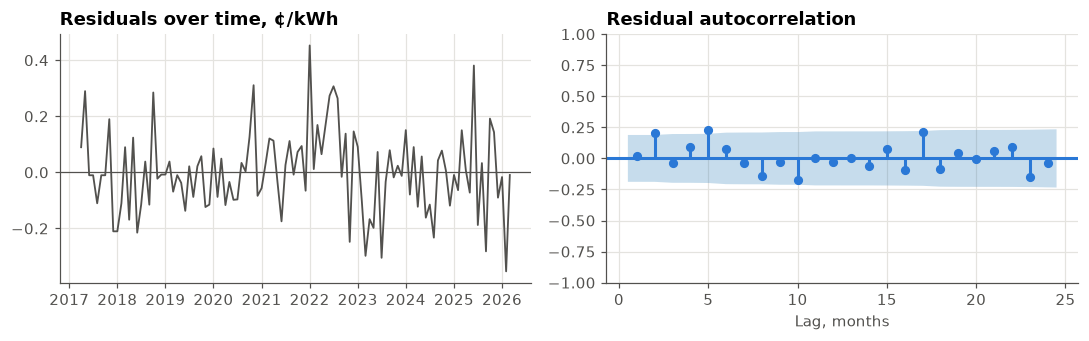

,lb_stat,lb_pvalue
12,19.17,0.06
24,33.64,0.07


In [12]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

final_sarima = auto_arima(price, m=12, D=1, with_intercept=True, suppress_warnings=True, error_action="ignore")
(p, d, q), (P, D, Q, m) = final_sarima.order, final_sarima.seasonal_order
print(f"Selected model: SARIMA({p},{d},{q})({P},{D},{Q})[{m}]")

# The first 13 residuals are start-up values distorted by differencing
resid = pd.Series(final_sarima.resid(), index=price.index).iloc[13:]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(resid, color=INK_2, lw=1.2)
axes[0].axhline(0, color=INK_2, lw=0.8)
axes[0].set(title="Residuals over time, ¢/kWh")
plot_acf(resid, lags=24, zero=False, ax=axes[1], color=COLORS["Naive"], vlines_kwargs={"colors": COLORS["Naive"]})
axes[1].set(title="Residual autocorrelation", xlabel="Lag, months")
plt.tight_layout()
plt.show()

acorr_ljungbox(resid, lags=[12, 24], model_df=p + q + P + Q).round(3)

On the full series, `auto_arima` selects SARIMA(0,1,0)(0,1,1)₁₂, a simpler model than the (0,1,1)(0,1,2)₁₂ chosen on the original training set, and one term away from the fixed SARIMA(0,1,1)(0,1,1)₁₂. The residuals are centred on zero, and no autocorrelation clearly exceeds the confidence band, although lags 2 and 5 sit at its edge. The Ljung–Box test doesn't reject the hypothesis of no autocorrelation at the 5% level (p = 0.06 at 12 lags and 0.07 at 24), but it's close, so the fit is adequate, with a little structure possibly left over. The one visible pattern is a run of positive residuals in 2022: the model under-predicted throughout the surge, which matches the backtest.

## 8. Forecast: April 2026 to March 2027

The final forecast refits drift, ETS and the auto-selected SARIMA on all 121 months and averages them. This is the forecast as it was committed, before the fixed SARIMA was added and before any later data arrived; the fixed SARIMA's forecast is shown alongside it in the table. Prediction intervals are **empirical**: they come from the spread of the average's actual errors at each horizon in the backtest (10th and 90th percentiles of the ratio of actual price to forecast), so they reflect how wrong this method has really been, surges included.

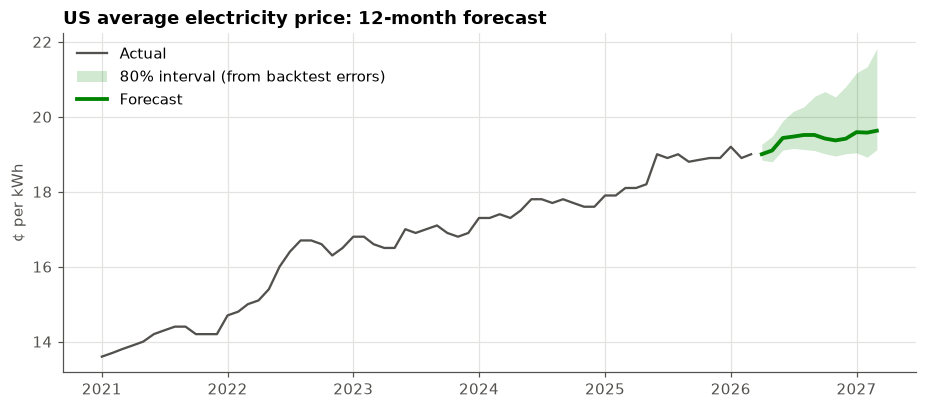

,forecast ¢,80% low ¢,80% high ¢,SARIMA (fixed) ¢
Apr 2026,19.00,18.84,19.27,18.97
May 2026,19.10,18.80,19.47,19.10
Jun 2026,19.43,19.11,19.89,19.65
Jul 2026,19.47,19.16,20.14,19.64
Aug 2026,19.51,19.13,20.26,19.70
Sep 2026,19.51,19.10,20.54,19.66
Oct 2026,19.42,19.01,20.67,19.58
Nov 2026,19.37,18.95,20.53,19.52
Dec 2026,19.42,19.01,20.81,19.56
Jan 2027,19.59,19.04,21.17,19.86


In [13]:
final_all = forecast_all(price, HORIZON)  # every model, fitted on data through March 2026
final = final_all["Average (drift, ETS, SARIMA)"]
idx = pd.date_range(price.index[-1] + pd.DateOffset(months=1), periods=HORIZON, freq="MS")

avg_bt = bt[bt["model"] == "Average (drift, ETS, SARIMA)"].assign(ratio=lambda d: d["actual"] / d["forecast"])
q = avg_bt.groupby("h")["ratio"].quantile([0.1, 0.9]).unstack()

outlook = pd.DataFrame({"forecast ¢": final, "80% low ¢": final * q[0.1].values,
                        "80% high ¢": final * q[0.9].values,
                        "SARIMA (fixed) ¢": final_all["SARIMA (fixed)"]}, index=idx)

fig, ax = plt.subplots(figsize=(10, 4))
recent = price["2021-01":]
ax.plot(recent, color=INK_2, lw=1.5, label="Actual")
ax.fill_between(idx, outlook["80% low ¢"], outlook["80% high ¢"], color=COLORS["Average (drift, ETS, SARIMA)"],
                alpha=0.18, lw=0, label="80% interval (from backtest errors)")
ax.plot(idx, outlook["forecast ¢"], color=COLORS["Average (drift, ETS, SARIMA)"], lw=2.5, label="Forecast")
ax.set(title="US average electricity price: 12-month forecast", ylabel="¢ per kWh")
ax.legend(loc="upper left")
plt.show()

outlook.set_axis(outlook.index.strftime("%b %Y"))

The forecast continues the recent upward trend, with seasonal bumps in the summer. The interval widens with the horizon and is skewed: the backtest's largest misses were under-forecasts during the surge, so the band reaches further above the forecast than below it.

## 9. How the forecasts have held up: April to October 2026

Everything above uses data through March 2026, where my capstone's dataset ended. BLS has since published seven more months. They were downloaded after the forecast in section 8 was finished and committed to this repository, so this is a true out-of-sample test. The new months are kept in a separate file, and nothing above this point reads it.

The original capstone didn't forecast beyond March 2026, because its 30 forecast months were its test window. To include it here, the same model and setup (SARIMA(0,1,1)(0,1,2)₁₂ with a constant, in $/kWh, with October 2025 dropped) is refitted on all the data through March 2026, as it would have been used at graduation.

In [14]:
new = pd.read_csv("data/APU000072610_bls_2025-01_to_2026-10.csv", parse_dates=["observation_date"],
                  index_col="observation_date")["APU000072610"] * 100
overlap = new[:price.index[-1]].dropna()
revised = (overlap - raw["APU000072610"][overlap.index] * 100).abs().gt(1e-9).sum()
actual_new = new[idx[0]:]
n_new = len(actual_new)
print(f"New months: {actual_new.index[0]:%b %Y} to {actual_new.index[-1]:%b %Y} ({n_new})")
print(f"Months in both files with a different value: {revised} of {len(overlap)}")

# The original capstone's model and setup, refitted on everything through March 2026
original_fit = SARIMAX(dollars_dropped.values, order=(0, 1, 1), seasonal_order=(0, 1, 2, 12), trend="c").fit(disp=False)
held_out = {name: fc[:n_new] for name, fc in final_all.items()}
held_out["Original capstone model, refitted"] = original_fit.forecast(n_new) * 100

scores = pd.DataFrame({
    "MAPE %": {name: mape(actual_new, fc) for name, fc in held_out.items()},
    "MAE ¢": {name: np.mean(np.abs(actual_new.values - fc)) for name, fc in held_out.items()},
}).sort_values("MAPE %")
backtest_same = bt[(bt["model"] == "Average (drift, ETS, SARIMA)") & (bt["h"] <= n_new)]["ape"].mean()
print(f"Backtest MAPE of the average over months 1–{n_new}, for comparison: {backtest_same:.1f}%")
scores

New months: Apr 2026 to Oct 2026 (7)
Months in both files with a different value: 0 of 14


Backtest MAPE of the average over months 1–7, for comparison: 1.8%


,MAPE %,MAE ¢
SARIMA (fixed),1.38,0.27
ETS,1.51,0.29
"Average (drift, ETS, SARIMA)",1.53,0.30
SARIMA (auto-selected),1.65,0.32
Drift,2.22,0.44
"Original capstone model, refitted",2.43,0.47
Naive,2.69,0.53
Seasonal naive,4.27,0.84


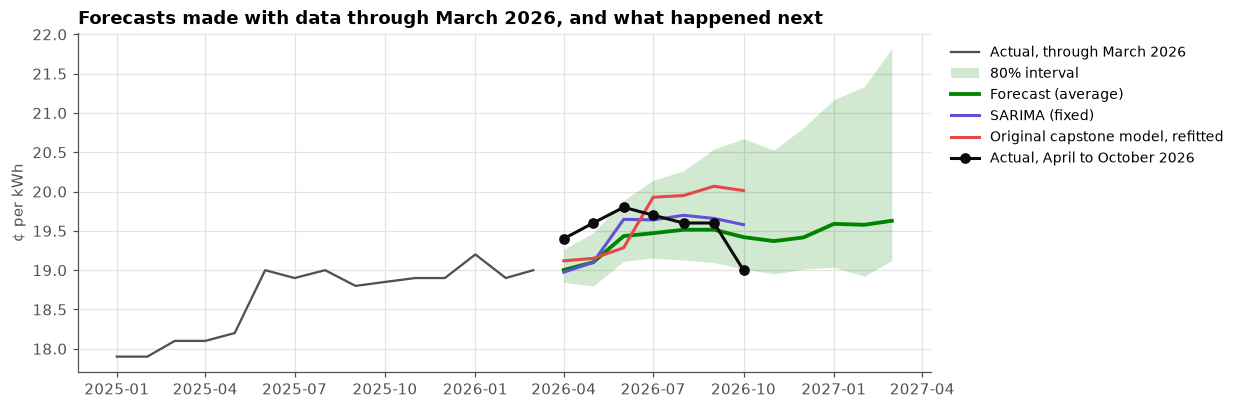

Actual price inside the 80% interval: 4 of 7 months


,forecast ¢,80% low ¢,80% high ¢,actual,inside 80% interval
Apr 2026,19.00,18.84,19.27,19.4,False
May 2026,19.10,18.80,19.47,19.6,False
Jun 2026,19.43,19.11,19.89,19.8,True
Jul 2026,19.47,19.16,20.14,19.7,True
Aug 2026,19.51,19.13,20.26,19.6,True
Sep 2026,19.51,19.10,20.54,19.6,True
Oct 2026,19.42,19.01,20.67,19.0,False


In [15]:
check = outlook.iloc[:n_new].drop(columns="SARIMA (fixed) ¢").assign(actual=actual_new.values)
check["inside 80% interval"] = check["actual"].between(check["80% low ¢"], check["80% high ¢"])
RED = "#e34948"

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(price["2025-01":], color=INK_2, lw=1.5, label="Actual, through March 2026")
ax.fill_between(idx, outlook["80% low ¢"], outlook["80% high ¢"], color=COLORS["Average (drift, ETS, SARIMA)"],
                alpha=0.18, lw=0, label="80% interval")
ax.plot(idx, outlook["forecast ¢"], color=COLORS["Average (drift, ETS, SARIMA)"], lw=2.5, label="Forecast (average)")
ax.plot(actual_new.index, held_out["SARIMA (fixed)"], color=COLORS["SARIMA (fixed)"], lw=2, label="SARIMA (fixed)")
ax.plot(actual_new.index, held_out["Original capstone model, refitted"], color=RED, lw=2,
        label="Original capstone model, refitted")
ax.plot(actual_new, color=INK, lw=2, marker="o", ms=6, label="Actual, April to October 2026")
ax.set(title="Forecasts made with data through March 2026, and what happened next", ylabel="¢ per kWh")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.show()

print(f"Actual price inside the 80% interval: {check['inside 80% interval'].sum()} of {n_new} months")
check.set_axis(check.index.strftime("%b %Y"))

- **The ranking matches the backtest.** The fixed SARIMA was the most accurate (1.4%), followed by ETS (1.5%), the average (1.5%) and the auto-selected SARIMA (1.7%), all ahead of drift (2.2%) and naive (2.7%). The fixed SARIMA was added to this notebook after these months were published, so for that model this is a check, not a blind test.
- **The size of the error was as expected.** The averaged forecast was off by 1.5% over the seven months. The backtest's figure for the same horizons was 1.8%.
- **The interval was too narrow early on.** It contained four of the seven prices. April and May came in above it, because prices rose faster in the spring than any model expected, and October's fall to 19.0¢ landed just below it. Seven months is too few to judge an 80% interval properly, but the two early misses suggest it understates the uncertainty in the first months.
- **The original capstone model, refitted, scored 2.4%,** between drift and naive. Its summer rise arrives a month after the actual one. That is the effect to expect from the dropped month, which shifts the seasonal pattern by one position (section 2).
- **Seven months can't rank the models reliably.** The ordering could change as more months arrive, and October's sharp fall shows how much a single month can move these averages.

## 10. What the evidence supports

- **A simple, fixed SARIMA was the best single method.** It was the most accurate over 1–12 months, the most consistent against the drift baseline, and the most accurate on the seven months published since.
- **Specification mattered more than model family.** The same SARIMA family, set up as in my original capstone (automatic order selection with an intercept), was no better than a naive forecast overall. With ten years of monthly data, a fixed standard structure was more reliable than re-selecting one each time.
- **Simple methods are hard to beat by much.** Drift and exponential smoothing came within 0.3 percentage points of the best model over 1–12 months.
- **Beyond 12 months, this analysis makes no claim,** because nothing longer was tested. The original capstone recommended SARIMA for horizons up to three years. Its own limitations section noted that ARIMA models lose accuracy over long horizons, and the growth of error with horizon here bears that out.
- **Two cautions.** The differences between methods come from 25 forecast origins and haven't been tested for statistical significance. And the fixed SARIMA was brought into this comparison after it did well in the natural gas extension, so its lead should be confirmed on future data. The larger risk for any of these forecasts is a shift like the 2021–22 surge, which none of them could anticipate from price history alone.

## Revisiting the original capstone

This notebook revises the version I submitted for the D214 capstone (April 2026), which is kept unchanged in [`D214-capstone-electricity-price-forecast/`](../../D214-capstone-electricity-price-forecast/). The question and data are the same.

The original did what the assignment asked: it built a SARIMA forecast from documented public data and evaluated it on a held-out period. Coming back to it, I saw several opportunities to make the evaluation more rigorous. I went through each one and decided how to handle it:

| In the original | In this revision | What I took from it |
|---|---|---|
| SARIMA evaluated on its own | Compared with ETS, three simple baselines and an average | In a more rigorous academic or business setting, a model needs a baseline to be judged against |
| One 30-month holdout (MAPE 0.77%) | 25-origin rolling backtest, 1–12 month horizons | One window measures one fit on one stretch of history; many windows show how the method does in general |
| Hypothesis: MAPE < 10% | Kept and reported; the main comparison is against baselines | The rubric required null and alternative hypotheses. Every method passes this one, so by itself it can't separate strong models from weak ones |
| October 2025 dropped (never collected, because of the government shutdown) | Interpolated as model input; excluded from scoring | Models need evenly spaced data, but a filled value isn't an observation |
| Model order chosen once by `auto_arima` | Re-selected at every origin, compared with a fixed standard SARIMA, and checked with residual diagnostics | Closer to how a model would be maintained in production. The fixed model turned out to be the more reliable of the two |
| Confidence intervals plotted | Intervals built from the backtest's actual errors | Intervals are most useful when they're checked against outcomes |
| SARIMA recommended for up to 3 years | A fixed SARIMA supported for 1–12 months; nothing claimed beyond that | A recommendation should reach only as far as the testing behind it |
| MAPE arguments reversed; units given as "kw/H" | Corrected | Small fixes |

The reasoning behind each decision is recorded in this project's [README](README.md#decision-log). The original report and slides are in [`D214-capstone-electricity-price-forecast/reports/`](../../D214-capstone-electricity-price-forecast/reports/).

## Limitations and next steps

- **Univariate.** The models see only past prices. The surge was driven by fuel costs, mainly natural gas, which none of them can see. The [natural gas extension](natural_gas_extension.ipynb) tests this by adding the Henry Hub gas price as a regressor. It finds that a lagged gas price adds little.
- **A national average.** It hides large regional differences and isn't meant for comparing places. State-level EIA data would support regional models.
- **Short history.** Ten years gives 25 quarterly origins, and the error estimates are noisy, especially for the surge period. The FRED series goes back to 1978, so a longer history could be tested to see whether older regimes still help.
- **Intervals.** The empirical intervals come from only 25 errors per horizon. Conformal prediction or a longer backtest would make them more reliable. The check in section 9 suggests they are too narrow for the first few months.

## References

- Bensaidani, A., & Deveaux, P. (2026, February 10). *Electricity prices in the U.S.: a significant economic and electoral concern in the run-up to the midterms.* BNP Paribas Economic Research.
- Huntington, H., & Liddle, B. (2022). How energy prices shape OECD economic growth: Panel evidence from multiple decades. *Energy Economics, 111*, 106082. https://doi.org/10.1016/j.eneco.2022.106082
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.). OTexts. https://otexts.com/fpp3/ (chapters 5.2 on simple baselines, 5.10 on time-series cross-validation, 13.4 on forecast combinations)
- U.S. Bureau of Labor Statistics. *Average Price: Electricity per Kilowatt-Hour in U.S. City Average* [APU000072610]. Retrieved from FRED, Federal Reserve Bank of St. Louis, April 21, 2026. https://fred.stlouisfed.org/series/APU000072610
- U.S. Bureau of Labor Statistics. *CPI: Average Price Data.* https://www.bls.gov/cpi/factsheets/average-prices.htm